# Rainfall simulation

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch
import matplotlib.pyplot as plt
from rainfall import *

In [3]:
# torch.manual_seed(2026)
data = simulate_data(T=100)

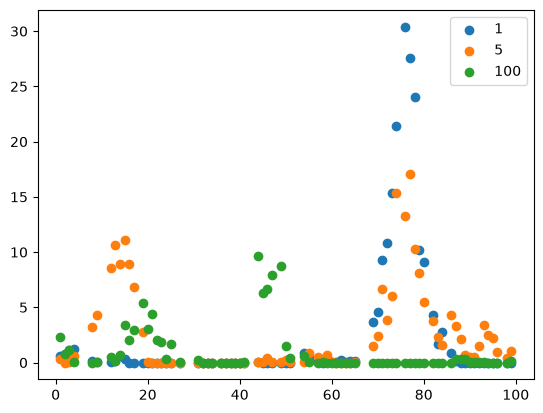

In [4]:
for i in [1,5, 100]:
    last = data[i]
    theta, stations, x, y, z = last
    plt.scatter(stations, z, label=f"{i}")
plt.legend()

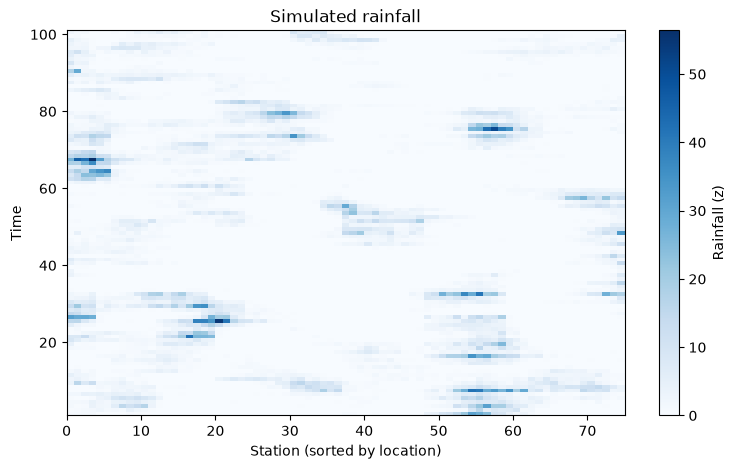

In [5]:
# Heatmap of rainfall (z) over time; skip t=0, which has no observations
stations = data[1][1]
Z = torch.stack([d[4] for d in data[1:]]).numpy()  # (T, m)

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(Z, aspect="auto", origin="lower", cmap="Blues",
               extent=[0, Z.shape[1], 1, Z.shape[0] + 1])
ax.set_xlabel("Station (sorted by location)")
ax.set_ylabel("Time")
ax.set_title("Simulated rainfall")
fig.colorbar(im, ax=ax, label="Rainfall (z)")
plt.show()

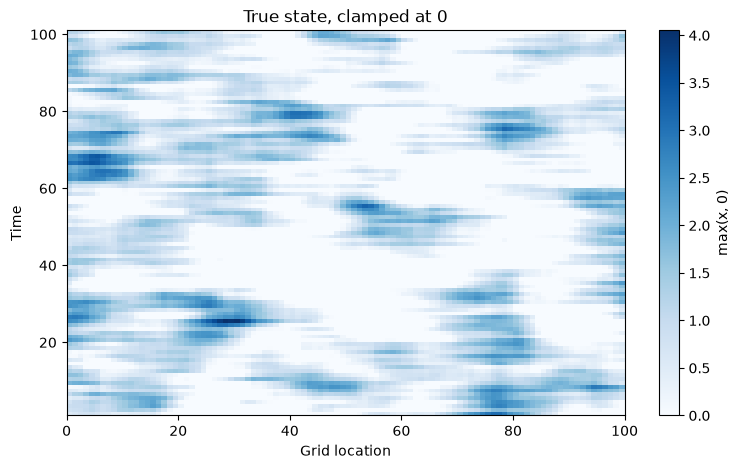

In [6]:
# Heatmap of the true latent state, clamped at 0, over time (all grid points)
X = torch.stack([d[2] for d in data[1:]]).clamp(min=0).numpy()  # (T, n)

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(X, aspect="auto", origin="lower", cmap="Blues",
               extent=[0, X.shape[1], 1, X.shape[0] + 1])
ax.set_xlabel("Grid location")
ax.set_ylabel("Time")
ax.set_title("True state, clamped at 0")
fig.colorbar(im, ax=ax, label="max(x, 0)")
plt.show()

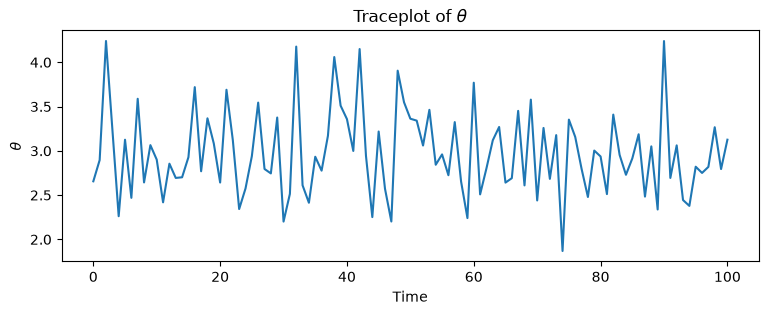

In [7]:
# Traceplot of the true theta over time
thetas = torch.stack([torch.as_tensor(d[0]) for d in data]).numpy()  # includes t=0

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(range(len(thetas)), thetas, lw=1.5)
ax.set_xlabel("Time")
ax.set_ylabel(r"$\theta$")
ax.set_title(r"Traceplot of $\theta$")
plt.show()

In [8]:
# Save as both .pt (torch) and .nc (NetCDF)
import os
os.makedirs("data", exist_ok=True)
save_data(data, "data/rainfall", n=100, m=75, T=100)